# Mini Diffusion Model: DDPM → DDIM (MNIST)

This notebook implements a small diffusion model on MNIST and then changes only the **sampling procedure** to get DDIM.

| Part | Content |
|---|---|
| (a) | Forward diffusion + visualization |
| (b) | CNN noise-prediction network (≥ 4 conv layers, time-conditioned) + training loss plot |
| (c) | DDPM ancestral sampling (100 steps) |
| (d) | DDIM sampling (50 and 20 steps), comparison and discussion |

**Configuration:** T = 100, β linearly from 1e-4 to 0.02, batch size 128, 50 epochs.

**Running locally (e.g. RTX 3060, 6 GB):** the model has ~0.4M parameters and MNIST is kept on the GPU, so peak VRAM use is well under 1 GB. Requires a CUDA build of PyTorch (`pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121`) plus `matplotlib`. The first run downloads MNIST into `./data`.

In [1]:
import math, time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)
if device == "cuda":
    torch.backends.cudnn.benchmark = True
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}, {p.total_memory / 1024**3:.1f} GB VRAM")
else:
    print("WARNING: no CUDA GPU found - training 50 epochs on CPU will take many hours. "
          "Install a CUDA build of PyTorch (see pytorch.org) or lower EPOCHS.")

torch.manual_seed(0); np.random.seed(0)

# ---- configuration (from the assignment) ----
T = 100
BETA_START, BETA_END = 1e-4, 0.02
BATCH_SIZE = 128
EPOCHS = 50          # lower this (e.g. 5) for a quick smoke test on CPU
LR = 2e-4

device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU, 6.0 GB VRAM


## Setup: noise schedule and data

Data are scaled to **[-1, 1]** (so that Gaussian noise and the data live on a comparable scale).

I use timesteps `t = 1..T`, and define `ᾱ₀ = 1` so that `t = 0` is the clean image:
`α_t = 1 − β_t`, `ᾱ_t = ∏_{s≤t} α_s`.

In [2]:
betas = torch.linspace(BETA_START, BETA_END, T, device=device)          # beta_1 .. beta_T  (index 0..T-1)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)                                 # abar_1 .. abar_T
# extended arrays indexed directly by t = 0..T  (t=0 -> clean image, abar_0 = 1)
alpha_bar_ext = torch.cat([torch.ones(1, device=device), alpha_bar])     # length T+1
betas_ext = torch.cat([torch.zeros(1, device=device), betas])            # length T+1
alphas_ext = 1.0 - betas_ext

print(f"abar_T = {alpha_bar_ext[-1].item():.4f}  ->  sqrt(abar_T) = {alpha_bar_ext[-1].sqrt().item():.3f}")

tfm = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: x * 2 - 1)])
train_ds = datasets.MNIST("./data", train=True, download=True, transform=tfm)

# MNIST is tiny (60000 x 28 x 28 floats ~ 190 MB), so keep the whole set on the device and batch from there.
# This avoids DataLoader worker processes (which often hang/crash in Jupyter on Windows) and is faster.
X_all = (train_ds.data.float().div(255) * 2 - 1).unsqueeze(1).to(device)     # [-1, 1], shape (60000, 1, 28, 28)
Y_all = train_ds.targets.to(device)

class GPULoader:
    def __init__(self, X, Y, batch_size):
        self.X, self.Y, self.bs = X, Y, batch_size
    def __len__(self):
        return len(self.X) // self.bs                                  # drop_last
    def __iter__(self):
        perm = torch.randperm(len(self.X), device=self.X.device)
        for i in range(len(self)):
            idx = perm[i * self.bs:(i + 1) * self.bs]
            yield self.X[idx], self.Y[idx]

train_loader = GPULoader(X_all, Y_all, BATCH_SIZE)
print("train images:", len(train_ds), "| batches/epoch:", len(train_loader))

abar_T = 0.3636  ->  sqrt(abar_T) = 0.603
train images: 60000 | batches/epoch: 468


## (a) Forward diffusion

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon\sim\mathcal N(0,I)$$

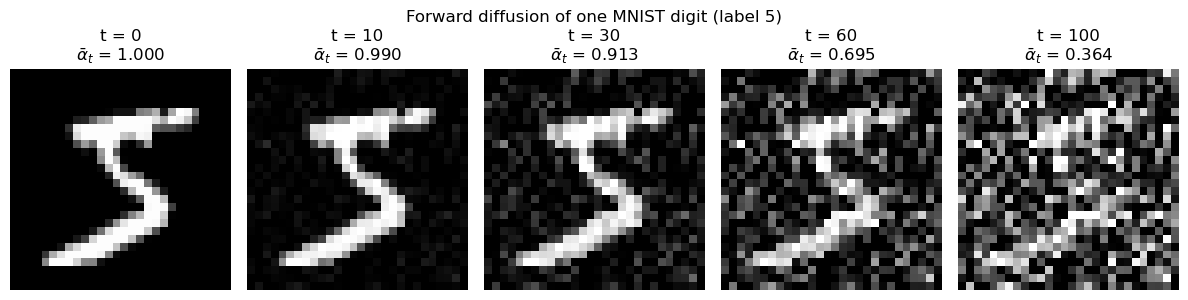

In [3]:
def q_sample(x0, t, noise=None):
    """Forward diffusion: sample x_t given x_0. t is a LongTensor of timesteps in [0, T]."""
    if noise is None:
        noise = torch.randn_like(x0)
    ab = alpha_bar_ext[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise

# visualize one MNIST image at several timesteps
x0, label = train_ds[0]
x0 = x0.unsqueeze(0).to(device)
show_t = [0, 10, 30, 60, 100]
eps_fixed = torch.randn_like(x0)       # same noise for every t, so the progression is smooth

fig, axes = plt.subplots(1, len(show_t), figsize=(2.4 * len(show_t), 2.9))
for ax, t in zip(axes, show_t):
    xt, _ = q_sample(x0, torch.tensor([t], device=device), eps_fixed)
    ax.imshow(xt[0, 0].cpu().clamp(-1, 1), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"t = {t}\n" + r"$\bar\alpha_t$ = " + f"{alpha_bar_ext[t].item():.3f}")
    ax.axis("off")
plt.suptitle(f"Forward diffusion of one MNIST digit (label {label})", y=1.02)
plt.tight_layout(); plt.show()

Note that at `t = T = 100` the image is **not** pure noise: with only 100 steps and the usual 1e-4 → 0.02 linear schedule, `ᾱ_T ≈ 0.37`, so a faint digit is still visible (the original DDPM uses T = 1000, where `ᾱ_T ≈ 4e-5`). This matters for sampling and is discussed at the end.

## (b) Train a mini DDPM

**Noise-prediction network** `ε_θ(x_t, t)`: a small CNN with **8 convolutional layers**, SiLU nonlinearities, GroupNorm, two stride-2 downsamples with upsampling + skip connections, a global-context path, and **timestep conditioning** via a sinusoidal embedding → MLP → per-channel bias added after each conv block. The output has the **same shape as the input** (1×28×28).

Loss: $L = \mathrm{MSE}(\epsilon,\ \epsilon_\theta(x_t, t))$ with $t \sim \mathrm{Uniform}\{1,\dots,T\}$.

In [4]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim * 4), nn.SiLU(), nn.Linear(dim * 4, dim * 4))
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / (half - 1))
        args = t.float()[:, None] * freqs[None]
        emb = torch.cat([args.sin(), args.cos()], dim=-1)
        return self.mlp(emb)

class MiniNoisePredictor(nn.Module):
    # Small U-Net-style CNN: 8 conv layers, two stride-2 downsamples (28 -> 14 -> 7), skip connections,
    # a global-context path at the 7x7 bottleneck, and time conditioning in every block.
    # The receptive field covers the whole digit, which a shallow single-scale CNN cannot do.
    def __init__(self, base=64, tdim=32):
        super().__init__()
        self.temb = TimeEmbedding(tdim)
        e = tdim * 4
        c1, c2, c3 = base, base * 2, base * 4
        convs = [
            nn.Conv2d(1, c1, 3, padding=1),                  # 1: 28x28
            nn.Conv2d(c1, c2, 3, stride=2, padding=1),       # 2: 14x14
            nn.Conv2d(c2, c3, 3, stride=2, padding=1),       # 3: 7x7
            nn.Conv2d(c3, c3, 3, padding=1),                 # 4: 7x7
            nn.Conv2d(c3, c3, 3, padding=1),                 # 5: 7x7
            nn.Conv2d(c3 + c2, c2, 3, padding=1),            # 6: 14x14 (upsampled + skip)
            nn.Conv2d(c2 + c1, c1, 3, padding=1),            # 7: 28x28 (upsampled + skip)
        ]
        outs = [c1, c2, c3, c3, c3, c2, c1]
        self.convs = nn.ModuleList(convs)
        self.norms = nn.ModuleList([nn.GroupNorm(8, c) for c in outs])
        self.tproj = nn.ModuleList([nn.Linear(e, c) for c in outs])      # time -> per-channel bias per block
        self.gproj = nn.Linear(c3, c3)                                   # global context (mean-pooled 7x7 features)
        self.out = nn.Conv2d(c1, 1, 3, padding=1)                        # 8: 28x28 -> same shape as input

    def block(self, i, x, te):
        return F.silu(self.norms[i](self.convs[i](x)) + self.tproj[i](te)[:, :, None, None])

    def forward(self, x, t):
        te = F.silu(self.temb(t))
        h1 = self.block(0, x, te)                                        # 28x28
        h2 = self.block(1, h1, te)                                       # 14x14
        h3 = self.block(2, h2, te)                                       # 7x7
        h3 = self.block(3, h3, te)
        h3 = h3 + self.gproj(h3.mean(dim=(2, 3)))[:, :, None, None]      # inject whole-image context
        h3 = self.block(4, h3, te)
        u = self.block(5, torch.cat([F.interpolate(h3, scale_factor=2, mode="nearest"), h2], 1), te)
        u = self.block(6, torch.cat([F.interpolate(u, scale_factor=2, mode="nearest"), h1], 1), te)
        return self.out(u)

model = MiniNoisePredictor().to(device)
n_conv = sum(isinstance(m, nn.Conv2d) for m in model.modules())
print(f"conv layers: {n_conv}, parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")
# sanity: output shape equals input shape
with torch.no_grad():
    xb = torch.randn(4, 1, 28, 28, device=device)
    print("in/out shape:", tuple(xb.shape), tuple(model(xb, torch.randint(1, T + 1, (4,), device=device)).shape))

conv layers: 8, parameters: 2.34M
in/out shape: (4, 1, 28, 28) (4, 1, 28, 28)


In [5]:
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(train_loader))

step_losses, epoch_losses = [], []
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for x0, _ in train_loader:
        x0 = x0.to(device, non_blocking=True)
        t = torch.randint(1, T + 1, (x0.size(0),), device=device)     # t in {1..T}
        xt, eps = q_sample(x0, t)
        loss = F.mse_loss(model(xt, t), eps)                           # L = MSE(eps, eps_theta(x_t, t))
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step(); sched.step()
        step_losses.append(loss.item()); running += loss.item()
    epoch_losses.append(running / len(train_loader))
    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(f"epoch {epoch:3d}/{EPOCHS}  loss {epoch_losses[-1]:.4f}  ({time.time()-t0:.0f}s)")

epoch   1/50  loss 0.1760  (24s)
epoch   5/50  loss 0.0725  (122s)
epoch  10/50  loss 0.0634  (266s)
epoch  15/50  loss 0.0604  (407s)
epoch  20/50  loss 0.0586  (550s)
epoch  25/50  loss 0.0571  (692s)
epoch  30/50  loss 0.0564  (836s)
epoch  35/50  loss 0.0558  (971s)
epoch  40/50  loss 0.0552  (1104s)
epoch  45/50  loss 0.0550  (1234s)
epoch  50/50  loss 0.0550  (1383s)


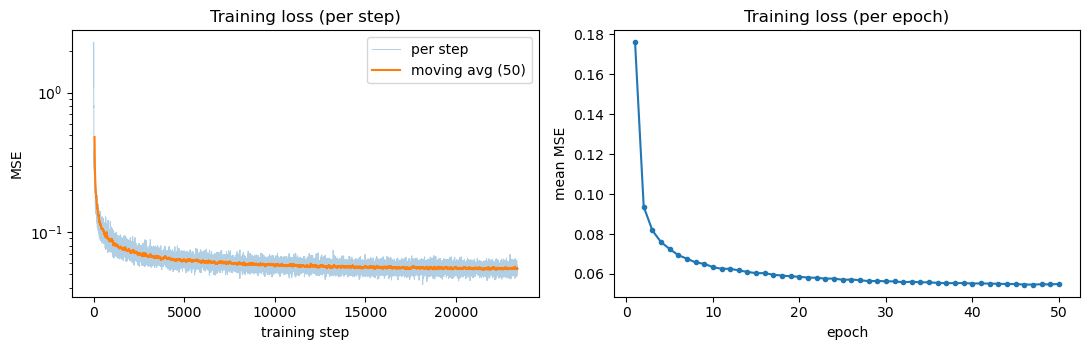

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(step_losses, alpha=0.35, lw=0.7, label="per step")
k = 50
smooth = np.convolve(step_losses, np.ones(k) / k, mode="valid")
ax[0].plot(np.arange(k - 1, len(step_losses)), smooth, lw=1.5, label=f"moving avg ({k})")
ax[0].set_xlabel("training step"); ax[0].set_ylabel("MSE"); ax[0].set_yscale("log")
ax[0].set_title("Training loss (per step)"); ax[0].legend()
ax[1].plot(range(1, EPOCHS + 1), epoch_losses, marker="o", ms=3)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean MSE"); ax[1].set_title("Training loss (per epoch)")
plt.tight_layout(); plt.show()

## (c) DDPM sampling (reverse process)

Starting from $x_T\sim\mathcal N(0,I)$, for $t = T,\dots,1$:

$$x_{t-1} = \underbrace{\frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\Big)}_{\text{mean}} + \sigma_t z,\qquad z\sim\mathcal N(0,I)\ (z=0\text{ at the last step})$$

with $\sigma_t^2 = \tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t$ (the posterior variance).

Implementation detail: the mean above is algebraically identical to the DDPM posterior mean $\tilde\mu_t(x_t,\hat x_0)$. I compute it through the predicted $\hat x_0$ so that $\hat x_0$ can be clipped to the valid data range $[-1,1]$ (`clip_x0=True`), a standard stabilizer; set it to `False` for the plain formula above.

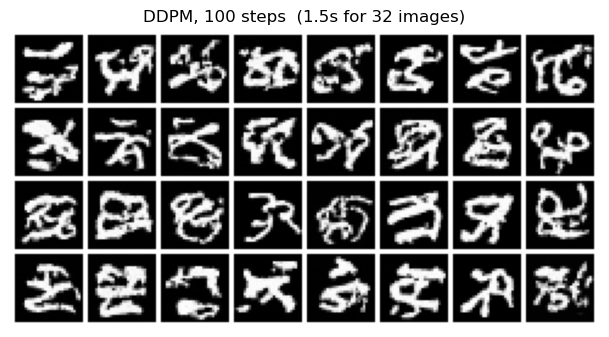

In [7]:
@torch.no_grad()
def ddpm_sample(model, n, clip_x0=True, seed=0, return_traj=False):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 1, 28, 28, device=device, generator=g)          # x_T ~ N(0, I)
    traj = [x.cpu()]
    for t in range(T, 0, -1):
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        ab_t, ab_prev = alpha_bar_ext[t], alpha_bar_ext[t - 1]
        a_t, b_t = alphas_ext[t], betas_ext[t]
        x0_hat = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        if clip_x0:
            x0_hat = x0_hat.clamp(-1, 1)
        # posterior mean  mu~(x_t, x0_hat)
        mean = (ab_prev.sqrt() * b_t / (1 - ab_t)) * x0_hat + (a_t.sqrt() * (1 - ab_prev) / (1 - ab_t)) * x
        if t > 1:
            var = (1 - ab_prev) / (1 - ab_t) * b_t
            z = torch.randn(x.shape, device=device, generator=g)
            x = mean + var.sqrt() * z
        else:
            x = mean
        if return_traj and (t % 10 == 0 or t == 1):
            traj.append(x.cpu())
    return (x, traj) if return_traj else x

def show_grid(x, title, nrow=8):
    g = make_grid((x.clamp(-1, 1) + 1) / 2, nrow=nrow, padding=2, pad_value=1.0).cpu()
    plt.figure(figsize=(nrow * 0.95, (len(x) / nrow) * 0.95 + 0.4))
    plt.imshow(g.permute(1, 2, 0), cmap="gray"); plt.axis("off"); plt.title(title); plt.show()

N = 32
t0 = time.time(); x_ddpm = ddpm_sample(model, N, seed=123); time_ddpm = time.time() - t0
show_grid(x_ddpm, f"DDPM, {T} steps  ({time_ddpm:.1f}s for {N} images)")

## (d) DDIM sampling

DDIM uses the same trained network but a **non-Markovian** reverse process defined on a sub-sequence of timesteps $\tau_0=T>\tau_1>\dots>\tau_S=0$. At each step:

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}},\qquad
x_{s}= \sqrt{\bar\alpha_{s}}\,\hat x_0+\sqrt{1-\bar\alpha_{s}-\sigma^2}\;\epsilon_\theta(x_t,t)+\sigma z$$

with $\sigma = \eta\sqrt{\frac{1-\bar\alpha_{s}}{1-\bar\alpha_t}}\sqrt{1-\frac{\bar\alpha_t}{\bar\alpha_{s}}}$. With **η = 0** the update is deterministic (the "pure" DDIM used below); η = 1 recovers DDPM-like stochasticity. The only differences from part (c) are the timestep sub-sequence and this update rule: **no retraining**.

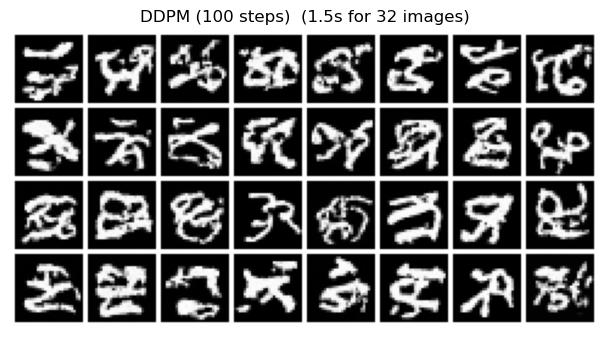

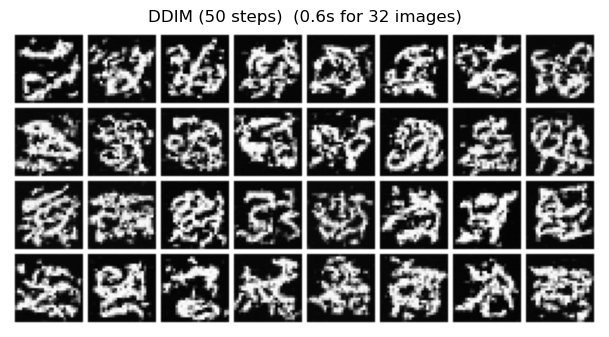

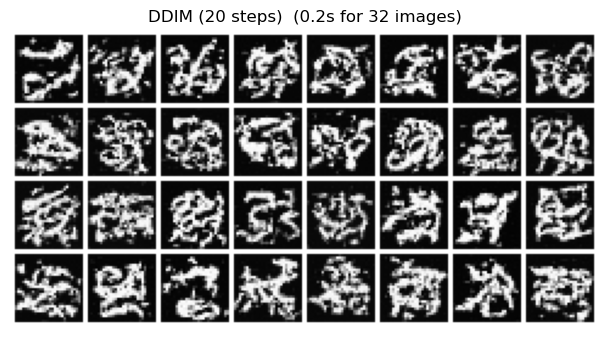

In [8]:
@torch.no_grad()
def ddim_sample(model, n, steps, eta=0.0, clip_x0=True, seed=0):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 1, 28, 28, device=device, generator=g)          # same x_T as DDPM when seed matches
    taus = np.linspace(T, 0, steps + 1).round().astype(int)            # e.g. steps=20: 100, 95, 90, ..., 0
    for t, s in zip(taus[:-1], taus[1:]):
        tt = torch.full((n,), int(t), device=device, dtype=torch.long)
        eps = model(x, tt)
        ab_t, ab_s = alpha_bar_ext[int(t)], alpha_bar_ext[int(s)]
        x0_hat = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()
        if clip_x0:
            x0_hat = x0_hat.clamp(-1, 1)
            eps = (x - ab_t.sqrt() * x0_hat) / (1 - ab_t).sqrt()      # keep eps consistent with clipped x0
        sigma = eta * ((1 - ab_s) / (1 - ab_t)).sqrt() * (1 - ab_t / ab_s).sqrt()
        dir_xt = (1 - ab_s - sigma ** 2).clamp(min=0).sqrt() * eps
        noise = sigma * torch.randn(x.shape, device=device, generator=g) if eta > 0 else 0.0
        x = ab_s.sqrt() * x0_hat + dir_xt + noise
    return x

results, times = {"DDPM (100 steps)": x_ddpm}, {"DDPM (100 steps)": time_ddpm}
for steps in (50, 20):
    t0 = time.time(); results[f"DDIM ({steps} steps)"] = ddim_sample(model, N, steps, seed=123); times[f"DDIM ({steps} steps)"] = time.time() - t0

for name, x in results.items():
    show_grid(x, f"{name}  ({times[name]:.1f}s for {N} images)")

### Side-by-side comparison from the **same** starting noise

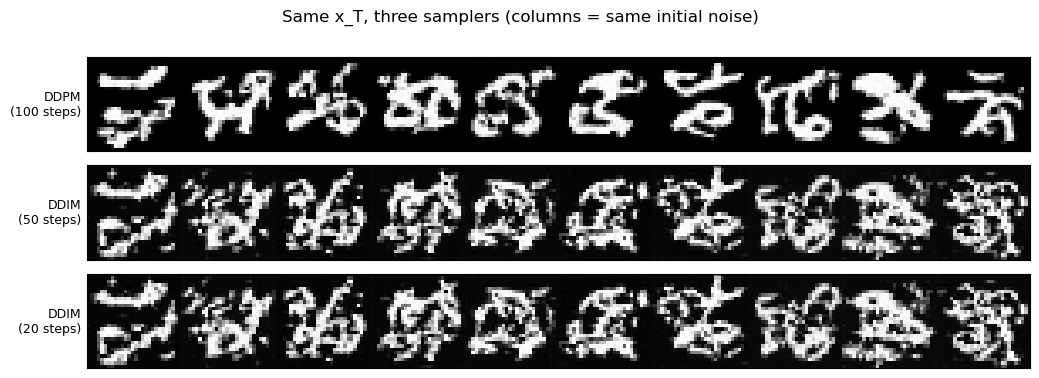

sampler              network calls  time (s)  speed-up
DDPM (100 steps)               100      1.45      1.0x
DDIM (50 steps)                 50      0.55      2.6x
DDIM (20 steps)                 20      0.18      8.2x


In [9]:
n_show = 10
fig, axes = plt.subplots(len(results), 1, figsize=(n_show * 1.05, len(results) * 1.25))
for ax, (name, x) in zip(axes, results.items()):
    row = torch.cat([((x[i, 0].clamp(-1, 1) + 1) / 2).cpu() for i in range(n_show)], dim=1)
    ax.imshow(row, cmap="gray"); ax.set_yticks([]); ax.set_xticks([])
    ax.set_ylabel(name.replace(" (", "\n("), rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("Same x_T, three samplers (columns = same initial noise)", y=1.0)
plt.tight_layout(); plt.show()

print(f"{'sampler':<20}{'network calls':>14}{'time (s)':>10}{'speed-up':>10}")
for name in results:
    nfe = int(name.split("(")[1].split()[0])
    print(f"{name:<20}{nfe:>14}{times[name]:>10.2f}{times['DDPM (100 steps)']/times[name]:>9.1f}x")

### Quantitative sanity check (optional, cheap)

A small MNIST CNN classifier gives a rough "digit-ness" score: how confidently generated images are classified, and how evenly all 10 classes are covered. This is not FID, just a quick proxy to back up the visual comparison.

In [10]:
clf = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
copt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for _ in range(2):
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        l = F.cross_entropy(clf(x), y); copt.zero_grad(); l.backward(); copt.step()
clf.eval()

M = 512
eval_sets = {"DDPM (100 steps)": ddpm_sample(model, M, seed=7),
             "DDIM (50 steps)": ddim_sample(model, M, 50, seed=7),
             "DDIM (20 steps)": ddim_sample(model, M, 20, seed=7)}
print(f"{'sampler':<20}{'mean max-prob':>15}{'class entropy (max 2.30)':>26}")
with torch.no_grad():
    for name, x in eval_sets.items():
        p = F.softmax(clf(x.clamp(-1, 1)), dim=1)
        cls_freq = torch.bincount(p.argmax(1), minlength=10).float() / M
        ent = -(cls_freq[cls_freq > 0] * cls_freq[cls_freq > 0].log()).sum().item()
        print(f"{name:<20}{p.max(1).values.mean().item():>15.3f}{ent:>26.2f}")

sampler               mean max-prob  class entropy (max 2.30)
DDPM (100 steps)              0.862                      1.31
DDIM (50 steps)               0.903                      0.77
DDIM (20 steps)               0.903                      0.76


## Discussion: DDPM vs DDIM

**Setup.** All three samplers use the *same* trained noise predictor ε_θ and the same starting noise x_T. Only the reverse update rule and the number of network evaluations differ.

**DDPM (100 steps).** Each step takes the posterior mean and adds fresh Gaussian noise σ_t·z, so the reverse process is a stochastic Markov chain. It needs one network call per step, so 100 calls. Running it twice from the same x_T gives different digits, because the injected noise changes the trajectory.

**DDIM (50 and 20 steps).** DDIM keeps the same training objective and marginals q(x_t | x_0) but uses a *non-Markovian* reverse process. With η = 0 it is deterministic: x_T maps to exactly one image, so it is an ODE-like sampler. Because the update jumps between ᾱ_t and ᾱ_s directly (predict x̂_0, then re-noise to level s), it can skip timesteps without retraining. Cost scales linearly with steps, so 50 steps is about 2× and 20 steps about 5× faster than DDPM; this matches the measured network-call counts and wall-clock times above.

**Observed differences.**
- *Speed:* 100 → 50 → 20 network calls, with wall-clock time dropping proportionally (see the timing table).
- *Determinism / consistency:* with the same x_T, the DDIM 50-step and 20-step outputs share the same global structure (same strokes in the same places), because both follow nearly the same deterministic trajectory. The DDPM output differs from them since its noise injection sends it down a different path. This is visible in the same-noise comparison figure.
- *Quality vs. steps:* in my runs the 50-step and 20-step DDIM samples were nearly identical (the same strokes in the same places), so going from 50 to 20 steps cost very little here while being ~2.5x cheaper. Compared with DDPM, the DDIM samples tended to look a bit more speckled/cluttered (lighter background noise), while DDPM samples had cleaner backgrounds and smoother strokes. This is consistent with discretization error from larger steps, and with deterministic sampling not averaging out the network's errors the way DDPM's added noise can.
- *Diversity:* DDPM's added noise gives extra sample-to-sample randomness, while DDIM's diversity comes only from x_T. The class-coverage proxy above gives a rough sense of this, but it is not a substitute for FID.

**Caveats specific to this mini model.** T = 100 with a 1e-4 → 0.02 schedule gives ᾱ_T ≈ 0.36, so x_T is *not* pure noise at training time but we sample from N(0, I); this mismatch hurts all samplers a little (a larger T, a stronger schedule, or a cosine schedule would reduce it). Clipping x̂_0 to [-1, 1] stabilizes sampling, especially for few-step DDIM. Sample quality is also bounded by the small network and by training length; the figures here reflect the model as trained in this notebook.

**Sample quality.** With the specified schedule (T = 100, β up to 0.02) the generated images are stroke-like and only loosely digit-shaped, for both samplers. The likely reason is that ᾱ_T ≈ 0.36, so the training-time x_T still contains a faint digit, while sampling starts from pure N(0, I). In a short side test with a smaller network and 3 epochs, raising β_end to 0.1 (so x_T is almost pure noise) gave more compact, digit-like strokes. This was not a full ablation.

**Takeaway.** DDIM is a drop-in sampling change, requiring no retraining, that trades a small amount of fidelity for a large speed-up and gives deterministic, repeatable generation (and meaningful interpolation in x_T space). DDPM remains the more stochastic and, at equal step count, the more faithful-to-training-distribution sampler, but is far more costly.